In [1]:
from pathlib import Path
import pickle

from analysis_codes import helpers, runners,diagnostics
# from diagnostics import *
import pystan
import matplotlib.pyplot as plt
import numpy as np
import logging
logger = logging.getLogger('pystan')

In [2]:
model = "models/bamf.stan"
datafile = "data/example_data.h5"


In [6]:


loaders = {"basic":runners.read_input ,"benchmark":runners.read_benchmark}
preprocessing_functions = {"nothing":runners.do_nothing, "basic":runners.basic_normalization}



iterations = 2000
seed = 1
delta = 0.9
treedepth = 12


picklename = Path(model).with_suffix(".pkl")
loaded_model = pickle.load(picklename.open('rb'))



# Diagnositics on un-normalized dataset

In [4]:
loader = "benchmark"
preprocessing = "nothing"
init_function = diagnostics.init_nothing

data, meta, extra = loaders[loader](Path(datafile))
data["p"] = 3
data, meta, extra = preprocessing_functions[preprocessing](data, meta, extra)
fitted = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=4, 
                               n_jobs=4, seed=seed,control={"adapt_delta":delta, 
                                                            "max_treedepth":treedepth})

In [5]:
checks = {"n_eff", "Rhat", "divergence", "treedepth", "energy"}
pystan.diagnostics.check_hmc_diagnostics(fitted, checks=checks,verbose=False)


{'n_eff': False,
 'Rhat': False,
 'divergence': False,
 'treedepth': True,
 'energy': True}

In [6]:
n_eff_ls_unnorm  = diagnostics.check_n_eff(fitted, pars=None, verbose=3)
rhat_ls_unnorm  = diagnostics.check_rhat(fitted, pars=None, verbose=3)

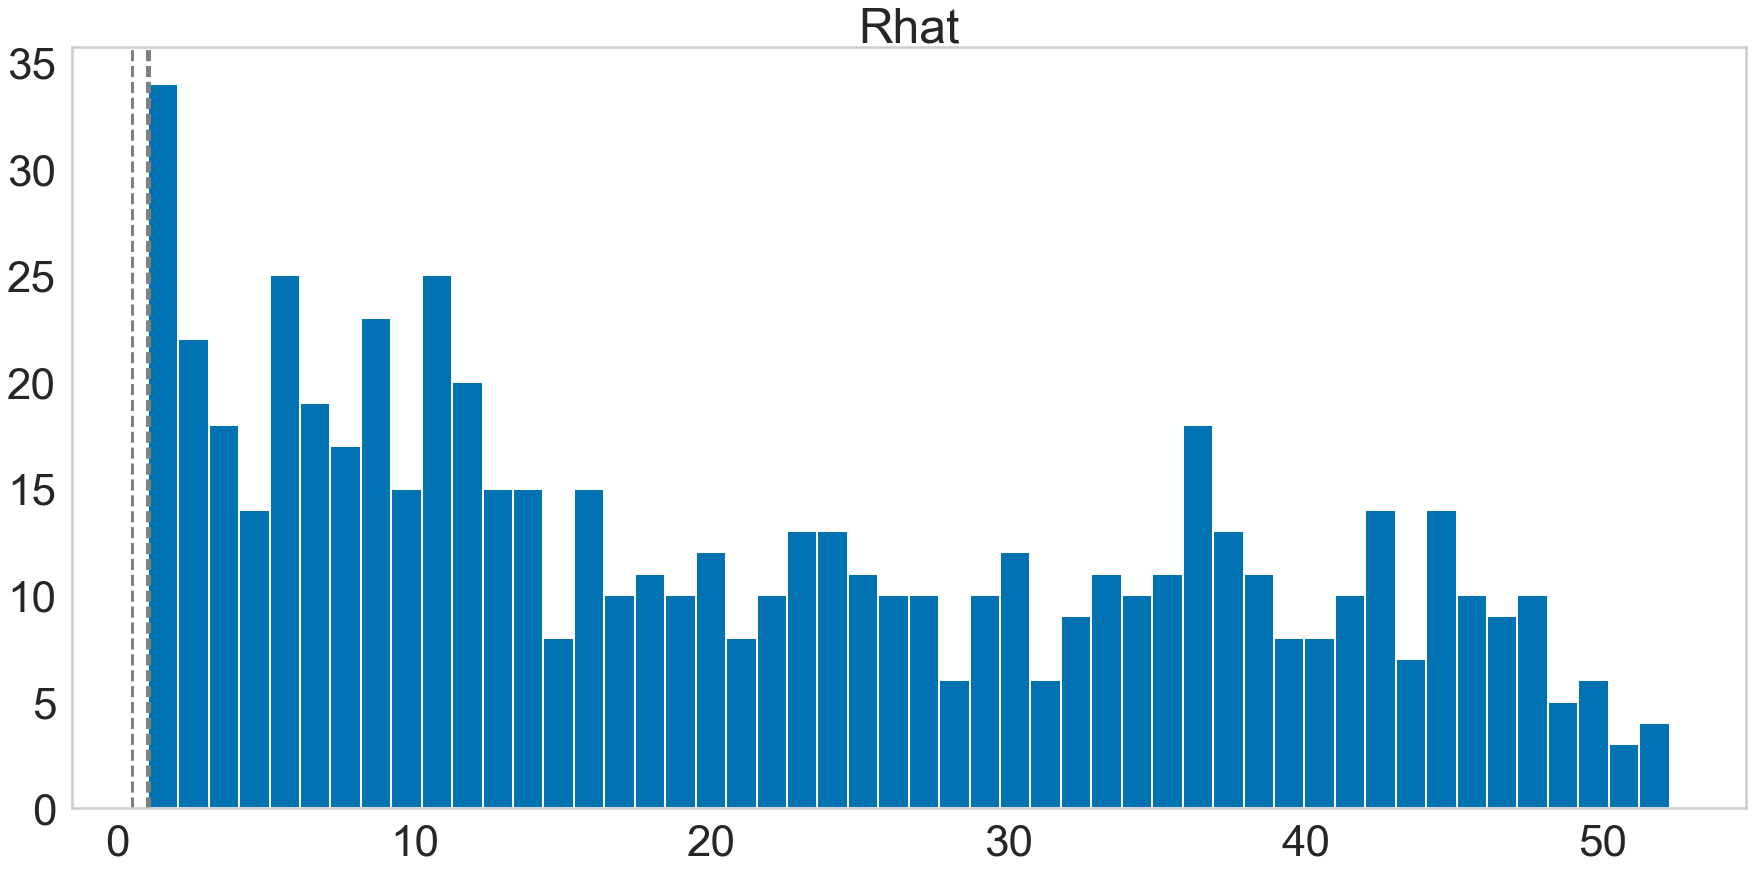

In [7]:
plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_unnorm.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()


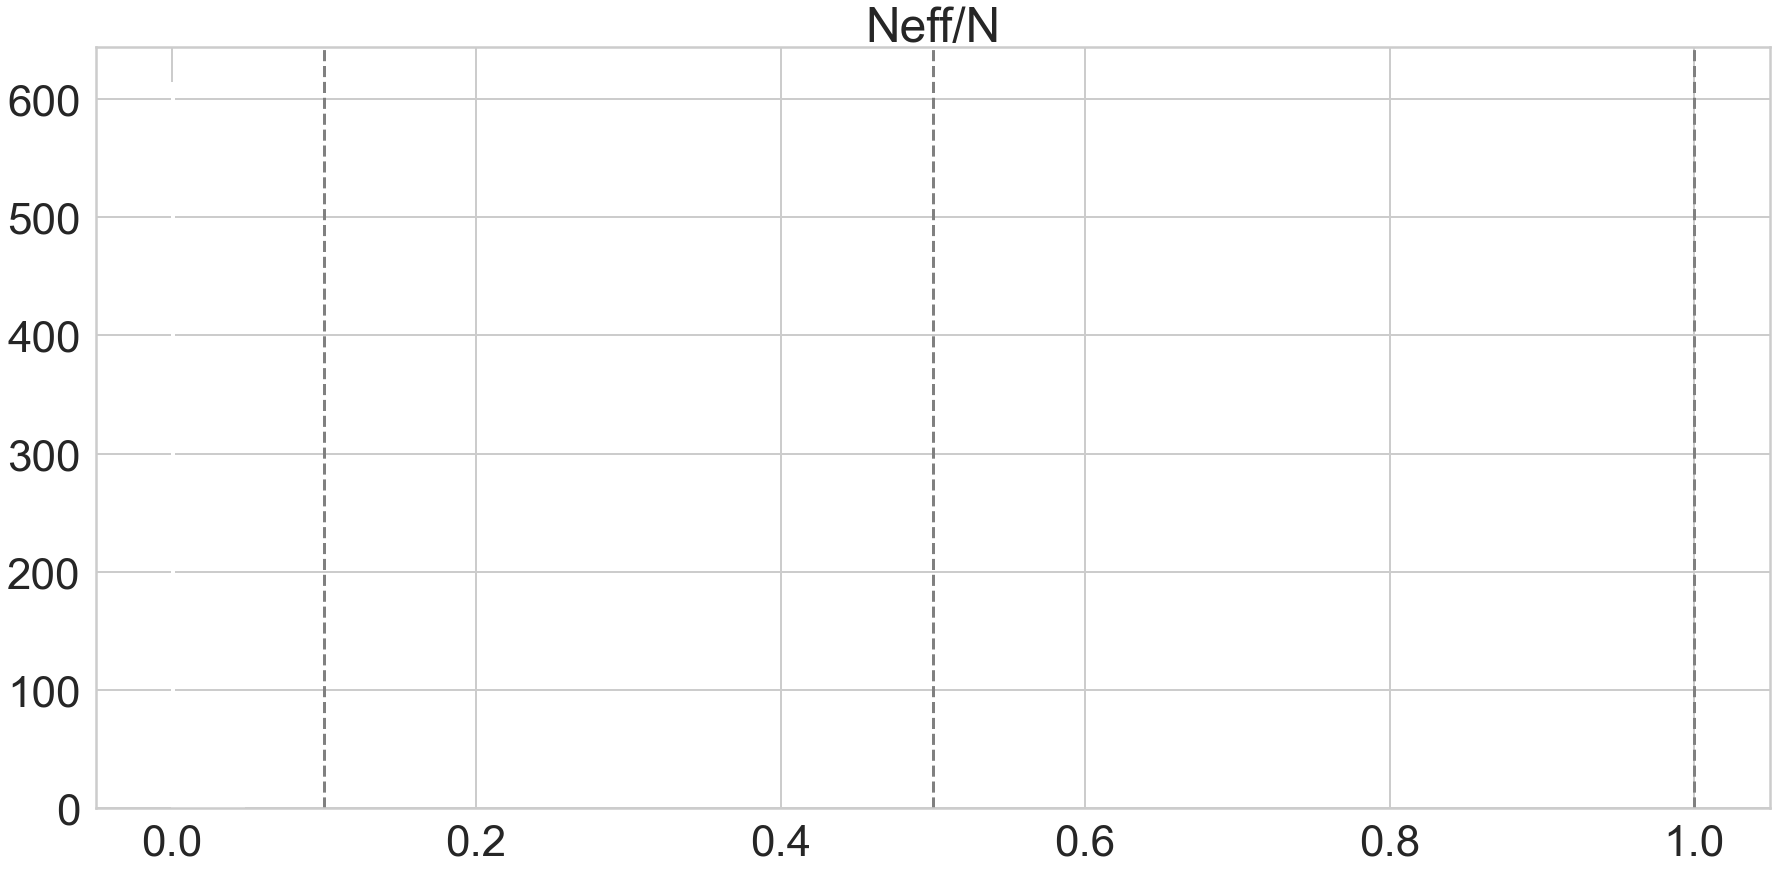

In [8]:
plt.figure()
plt.title('Neff/N')
plt.hist(n_eff_ls_unnorm.values(),bins = 50)
# plt.xlim([0,1])
plt.axvline(0.1,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
# plt.gca().invert_yaxis()

# Diagnositics on normalized dataset

In [9]:
loader = "benchmark"
preprocessing = "basic"
init_function = diagnostics.init_nothing



In [10]:
data, meta, extra = loaders[loader](Path(datafile))
data["p"] = 3
data, meta, extra = preprocessing_functions[preprocessing](data, meta, extra)
fitted = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=4, 
                               n_jobs=4, seed=seed,control={"adapt_delta":delta, "max_treedepth":treedepth})

In [11]:
checks = {"n_eff", "Rhat", "divergence", "treedepth", "energy"}
pystan.diagnostics.check_hmc_diagnostics(fitted, checks=checks,verbose=False)


{'n_eff': False,
 'Rhat': False,
 'divergence': True,
 'treedepth': True,
 'energy': True}

In [12]:
n_eff_ls_norm  = diagnostics.check_n_eff(fitted, pars=None, verbose=3)
rhat_ls_norm  = diagnostics.check_rhat(fitted, pars=None, verbose=3)

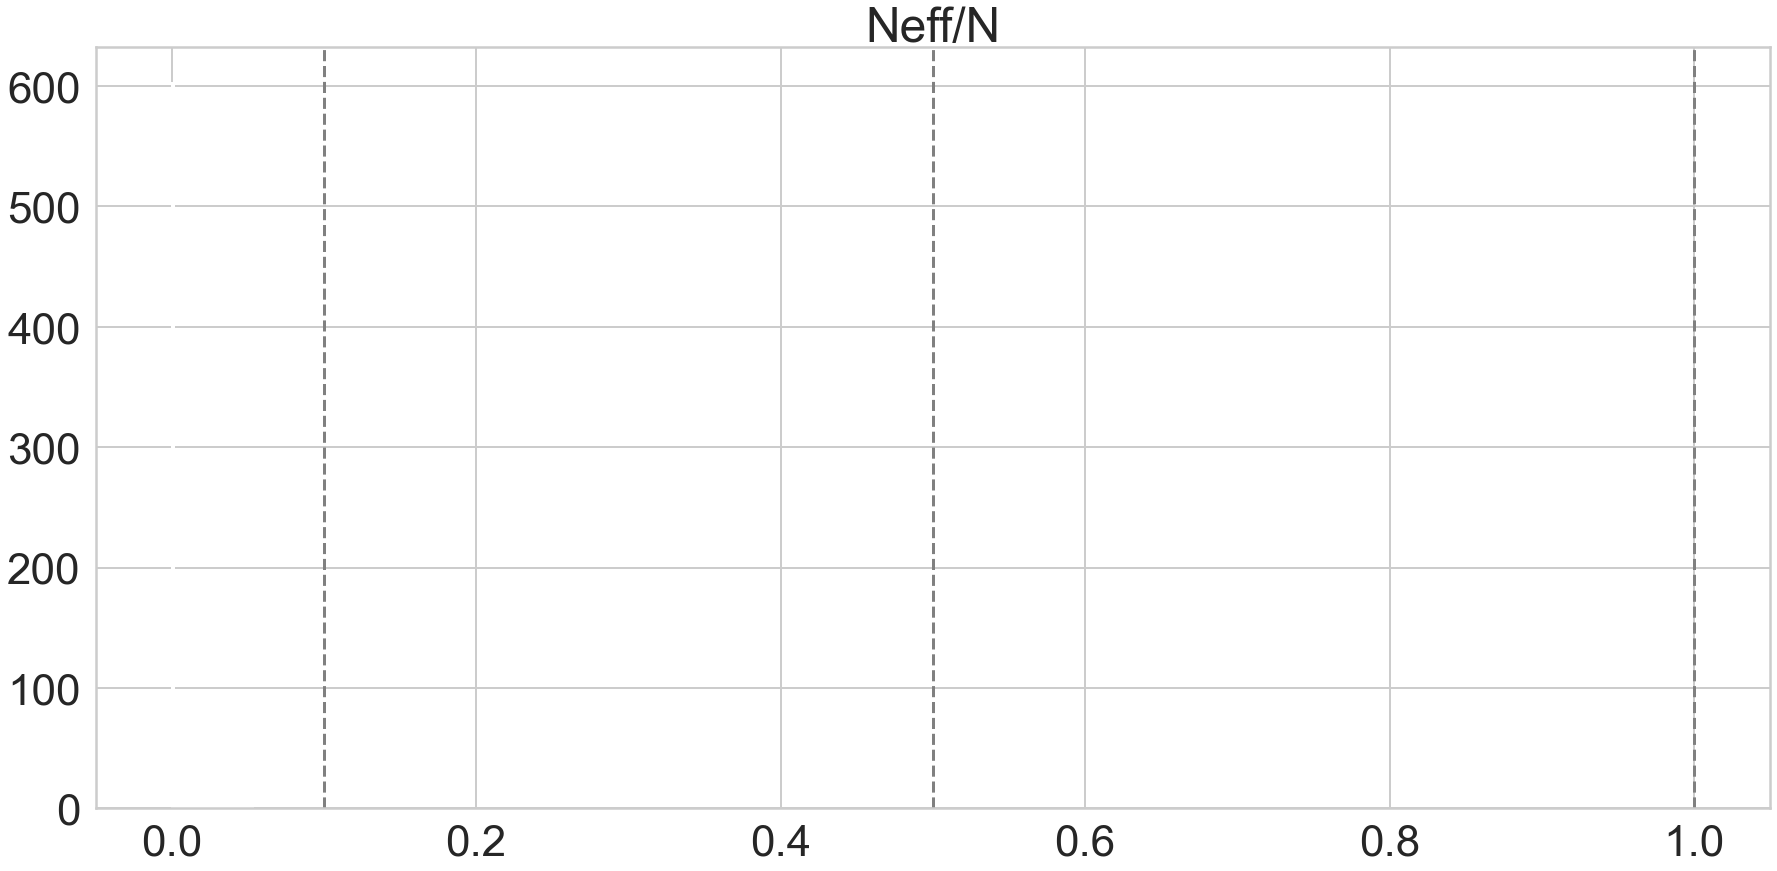

In [13]:
plt.figure()
plt.title('Neff/N')
plt.hist(n_eff_ls_norm.values(),bins = 50)
# plt.xlim([0,1])
plt.axvline(0.1,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
# plt.gca().invert_yaxis()

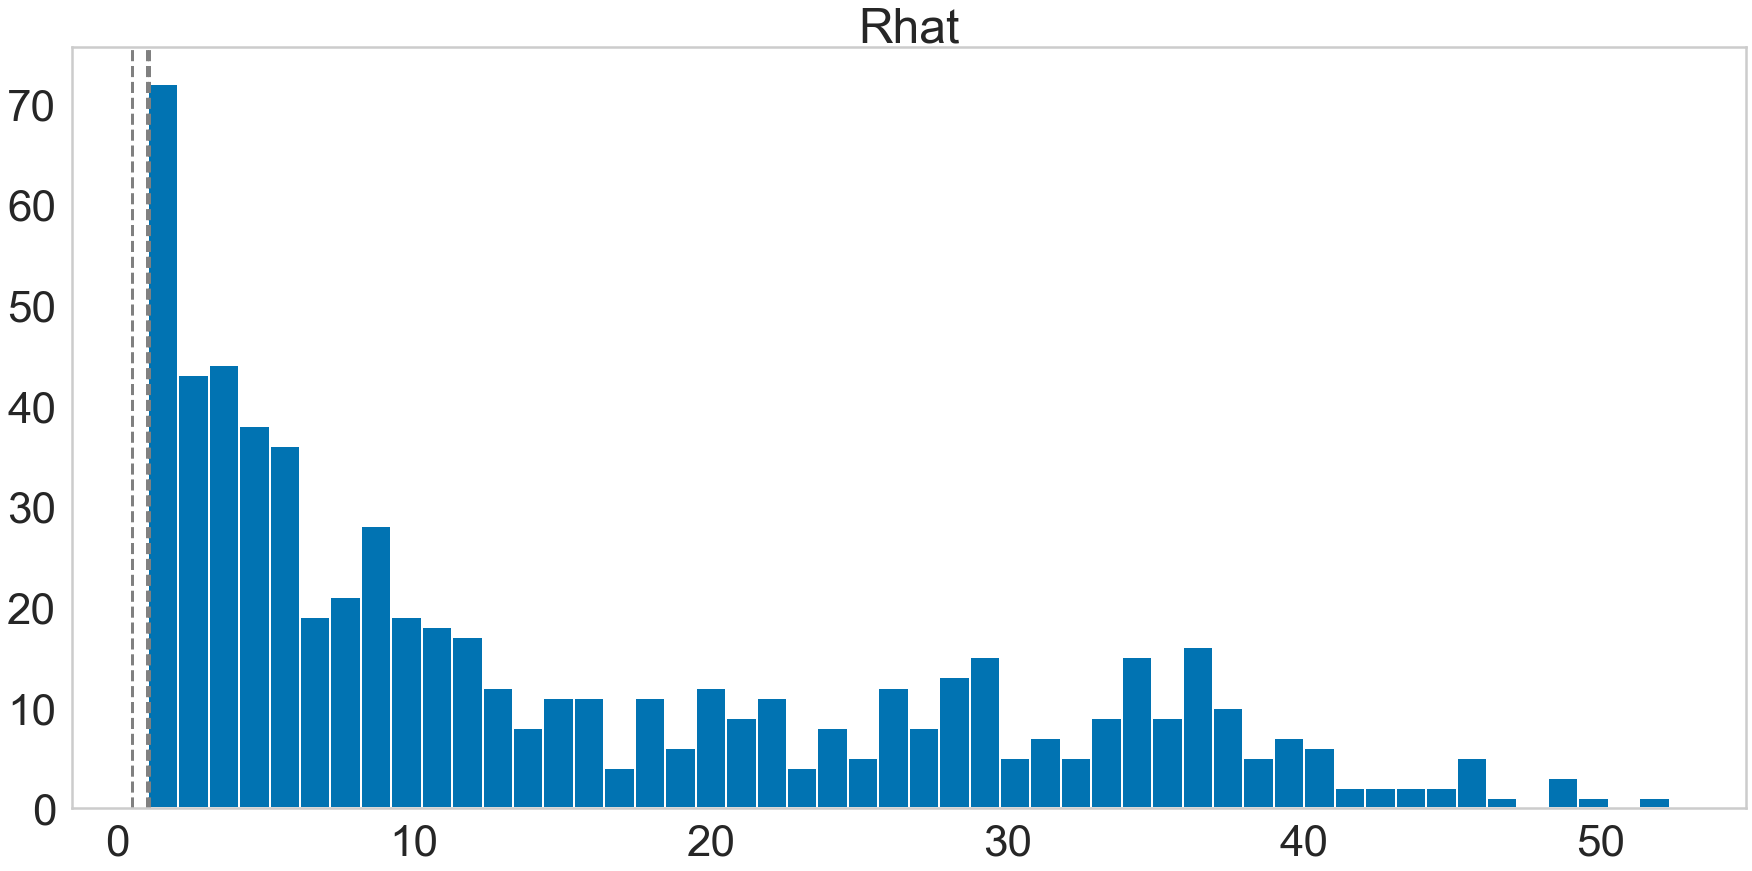

In [14]:

plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()



# Diagnositics on normalized & initilization

In [12]:
initoptions={'premodel': 'models/bamf.stan', 'premodel_options': {'iter': 2000}}
model = "models/bamf.stan"
datafile = "data/longer_data.h5"


In [13]:
def model_init():

    preoptions = {}

    if "premodel_options" in initoptions:
        preoptions.update(initoptions["premodel_options"])

    inits = premodel.optimizing(data, **preoptions, as_vector=True)

    return inits

In [18]:
loader = "benchmark"
preprocessing = "basic"
iterations = 2000
init_function = model_init
seed = 5435887
delta = 0.9
treedepth = 12

premodel = None
if "premodel" in initoptions:
    if type(initoptions["premodel"]) is list:
        premodel = []
        for k in initoptions["premodel"]:
            prepicklename = Path(k).with_suffix(".pkl")
            premodel.append(pickle.load(prepicklename.open('rb')))      
    else:
        prepicklename = Path(initoptions["premodel"]).with_suffix(".pkl")
        premodel = pickle.load(prepicklename.open('rb'))

data, meta, extra = loaders[loader](Path(datafile))


In [19]:

data, meta, extra = preprocessing_functions[preprocessing](data, meta, extra)
data["p"] = 3
fitted = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=1, 
                               n_jobs=1, seed=seed,control={"adapt_delta":delta, 
                                                            "max_treedepth":treedepth})

KeyboardInterrupt: 

In [20]:
preoptions = {}

if "premodel_options" in initoptions:
    preoptions.update(initoptions["premodel_options"])

In [21]:
data

{'X': array([[0.30700307, 0.14267753, 0.96824924, ..., 0.04550963, 0.08613606,
         0.03105705],
        [0.70647897, 0.32905878, 2.20005094, ..., 0.11800331, 0.19738809,
         0.07184699],
        [0.81394306, 0.37919061, 2.5508363 , ..., 0.1190188 , 0.22371811,
         0.08300289],
        ...,
        [1.2278209 , 0.57000835, 3.86293202, ..., 0.20259579, 0.35142986,
         0.12356742],
        [1.15367036, 0.53556247, 3.65553163, ..., 0.16594379, 0.32551312,
         0.11633765],
        [0.95794796, 0.4447832 , 3.03125423, ..., 0.1402306 , 0.27039082,
         0.09663232]]),
 'm': 74,
 'n': 337,
 'sigma': array([[0.00855964, 0.00523437, 0.01415373, ..., 0.00121757, 0.00131761,
         0.00101291],
        [0.00913538, 0.00565379, 0.01511376, ..., 0.00145925, 0.00165042,
         0.00117743],
        [0.00928417, 0.0057614 , 0.01537619, ..., 0.00146235, 0.00171979,
         0.00121856],
        ...,
        [0.0098362 , 0.00615379, 0.01632044, ..., 0.00169833, 0.00202277,

In [22]:
premodel.optimizing(data, **preoptions, as_vector=True,seed=seed)

OrderedDict([('G',
              array([[15.73644697,  1.45180841,  9.81152072],
                     [38.90714707,  0.4542426 , 22.57767068],
                     [41.9898758 ,  0.18722899, 27.39352852],
                     ...,
                     [60.75835946, 12.05879081, 38.23116489],
                     [66.82508634,  1.10443007, 34.62714592],
                     [51.75657025,  3.73470485, 29.6658987 ]])),
             ('F',
              array([[8.67254195e-03, 3.96251495e-03, 2.81138332e-02, 3.42681111e-04,
                      9.66660632e-04, 3.38613274e-03, 1.81653446e-02, 4.75527820e-02,
                      8.75516144e-02, 3.18148783e-02, 2.14690314e-02, 3.66054128e-03,
                      6.53144232e-03, 3.34621021e-02, 1.37158346e-02, 5.95140437e-02,
                      2.64653984e-02, 1.06800870e-01, 9.44002511e-02, 1.34616511e-02,
                      3.52882793e-12, 5.35776046e-03, 1.96083201e-03, 6.10141512e-03,
                      6.70490964e-03, 2.22666